# EDA — Airbus Ship Detection

Мета: подивитись на дані до побудови моделі — скільки знімків порожні, скільки кораблів на знімку,
як виглядають маски.

Працюємо локально: повний CSV + вибірка з 300 знімків у `data/train_micro/`
(150 без кораблів, 75 з одним, 75 з двома і більше).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from rle import rle_decode, rle_encode

DATA_DIR = ROOT / "data"
IMAGES_DIR = DATA_DIR / "train_micro"
SEED = 42

## 1. Скільки знімків і кораблів

У CSV один рядок = один корабель. Знімок без кораблів — один рядок з порожнім `EncodedPixels` (NaN).

In [2]:
df = pd.read_csv(DATA_DIR / "train_ship_segmentations_v2.csv")
ships_per_image = df.groupby("ImageId")["EncodedPixels"].count()

print("рядків у CSV:", len(df))
print("знімків:", len(ships_per_image))
print("кораблів:", ships_per_image.sum())
print(f"частка знімків без кораблів: {(ships_per_image == 0).mean():.1%}")

рядків у CSV: 231723
знімків: 192556
кораблів: 81723
частка знімків без кораблів: 77.9%


## 2. Розподіл кількості кораблів на знімку

Ліворуч — усі знімки: стовпчик «0» домінує, це і є дисбаланс класів.
Праворуч — лише знімки з кораблями, щоб було видно форму «хвоста».

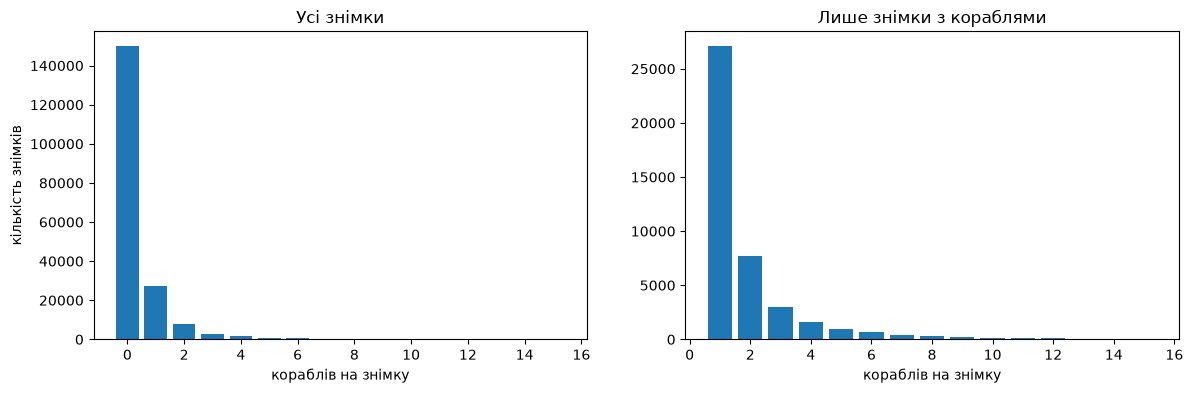

In [3]:
counts = ships_per_image.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(counts.index, counts.values)
axes[0].set_title("Усі знімки")
axes[0].set_xlabel("кораблів на знімку")
axes[0].set_ylabel("кількість знімків")

with_ships = counts[counts.index > 0]
axes[1].bar(with_ships.index, with_ships.values)
axes[1].set_title("Лише знімки з кораблями")
axes[1].set_xlabel("кораблів на знімку")
plt.show()

## 3. Знімки з масками

Декодуємо RLE кожного корабля в маску 768×768 і накладаємо червоним на знімок.
**Перевірка:** червоні плями мають лягати точно на кораблі. Якщо переплутати порядок пікселів
(рядки vs стовпці), маска виявиться дзеркально відбитою по діагоналі — це одразу видно.

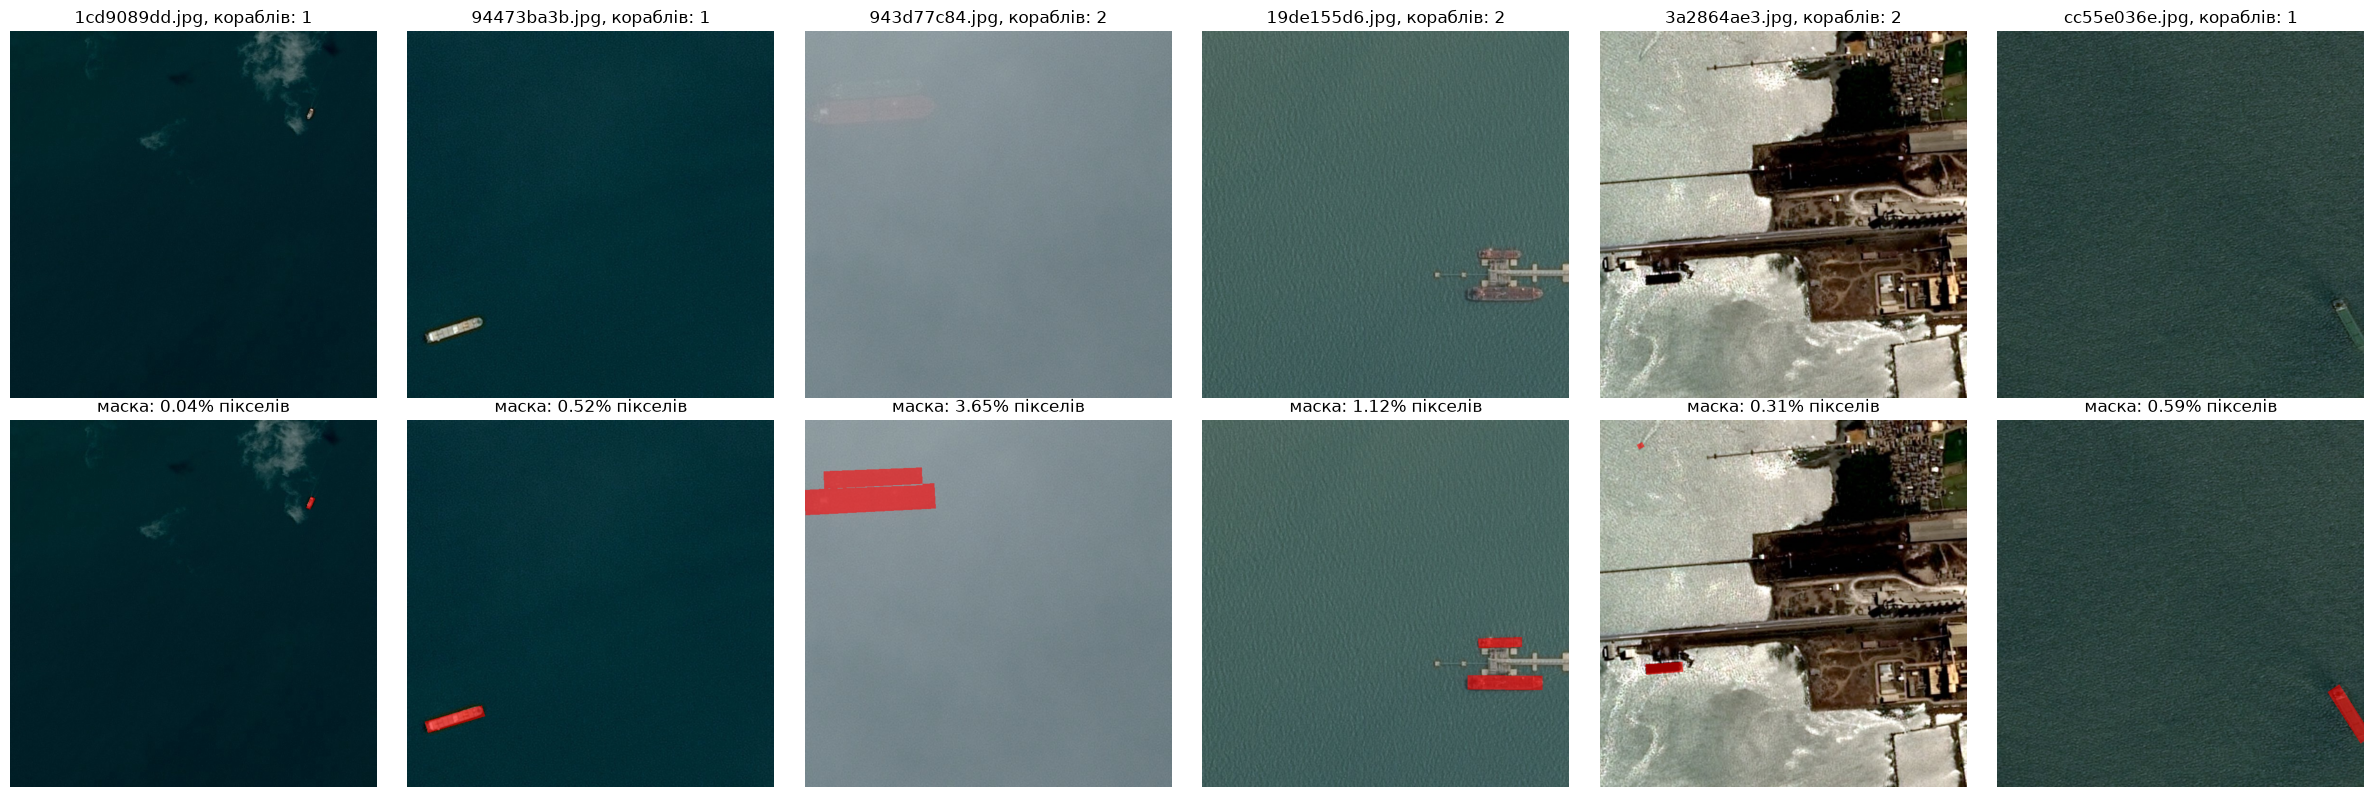

In [4]:
def ship_mask(image_id):
    mask = np.zeros((768, 768), dtype=np.uint8)
    for encoded in df.loc[df["ImageId"] == image_id, "EncodedPixels"].dropna():
        mask |= rle_decode(encoded)
    return mask


sample = pd.read_csv(DATA_DIR / "sample_ids.csv")
shown = sample[sample["n_ships"] > 0].sample(6, random_state=SEED)

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for col, (image_id, n_ships) in enumerate(zip(shown["ImageId"], shown["n_ships"])):
    image = plt.imread(IMAGES_DIR / image_id)
    mask = ship_mask(image_id)

    axes[0, col].imshow(image)
    axes[0, col].set_title(f"{image_id}, кораблів: {n_ships}")
    axes[1, col].imshow(image)
    axes[1, col].imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.6)
    axes[1, col].set_title(f"маска: {mask.mean():.2%} пікселів")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Перевірка RLE: decode → encode

`rle_encode` робить зворотне до `rle_decode`: маска → рядок. Якщо обидві функції правильні,
то `rle_encode(rle_decode(s)) == s` для кожного корабля. `rle_encode` знадобиться для сабміту:
передбачену моделлю маску треба перетворити на рядок.

Перевіряємо на всіх кораблях зі знімків `train_micro`.

In [5]:
micro_original_rles = df[df["ImageId"].isin(sample["ImageId"])]["EncodedPixels"].dropna()
mismatched_rles = [
    original_rle
    for original_rle in micro_original_rles
    if rle_encode(rle_decode(original_rle)) != original_rle
]

print("перевірено кораблів:", len(micro_original_rles))
print("розбіжностей:", len(mismatched_rles))

перевірено кораблів: 325
розбіжностей: 0


## 5. Розміри кораблів

Площа корабля в пікселях = сума всіх довжин у його RLE-рядку (кожна пара — «початок, довжина»).
Маску декодувати не треба, тому рахуємо по **всіх** кораблях повного CSV.

Навіщо: зрозуміти, наскільки дрібні кораблі, і що з ними станеться, якщо зменшити знімок
з 768 до 384 чи 256 (площа зменшується в 4 чи 9 разів).

In [6]:
def ship_area(encoded_pixels):
    return sum(int(length) for length in encoded_pixels.split()[1::2])


areas = df["EncodedPixels"].dropna().map(ship_area)
image_area = 768 * 768

print(areas.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0))
print(f"\nмедіанний корабель займає {areas.median() / image_area:.3%} площі знімка")
for size in [768, 384, 256]:
    scale = (size / 768) ** 2
    small = (areas * scale < 50).mean()
    print(f"знімок {size}×{size}: медіана {areas.median() * scale:.0f} пікс., "
          f"кораблів менших за 50 пікс.: {small:.1%}")

count    81723.0
mean      1567.0
std       2842.0
min          2.0
10%         52.0
25%        111.0
50%        408.0
75%       1550.0
90%       4872.0
max      25904.0
Name: EncodedPixels, dtype: float64

медіанний корабель займає 0.069% площі знімка
знімок 768×768: медіана 408 пікс., кораблів менших за 50 пікс.: 9.2%
знімок 384×384: медіана 102 пікс., кораблів менших за 50 пікс.: 37.6%
знімок 256×256: медіана 45 пікс., кораблів менших за 50 пікс.: 51.6%


Гістограма в логарифмічному масштабі по осі X: розміри відрізняються в сотні разів,
у звичайному масштабі всі дрібні кораблі злиплися б в один стовпчик.

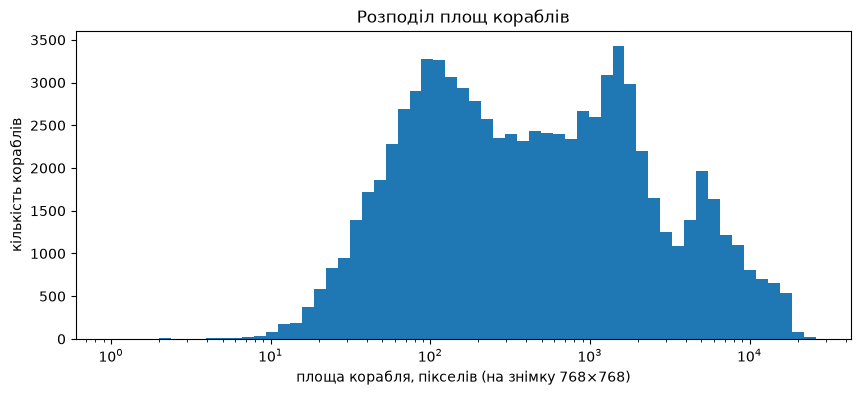

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(areas, bins=np.logspace(0, np.log10(areas.max()), 60))
ax.set_xscale("log")
ax.set_xlabel("площа корабля, пікселів (на знімку 768×768)")
ax.set_ylabel("кількість кораблів")
ax.set_title("Розподіл площ кораблів")
plt.show()